# 02 - Modelling

Steps covered here:

1. **Evaluation setup**: development set for cross-validation, walk-forward test
2. **Baseline**: how well does the draft pick alone predict VORP in years 3-4?
3. **Models with the window features**: Ridge, Ridge with splines, gradient boosting,
   an ensemble; where the gain comes from (ablation); calibration; floor and ceiling

All rules live in `src/modelling.py`, so every notebook evaluates models the same way.
The test classes (2017-2022) are **not** touched in this notebook.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2, SURFACE

apply_style()
df = m.load_table()
dev = m.dev_set(df)
print(f"In-scope players: {len(df)}")
print(f"Development set (CV): {len(dev)} players, classes {dev['draft_year'].min()}-{dev['draft_year'].max()}")

In-scope players: 1180
Development set (CV): 683 players, classes 2000-2013


## 1. Evaluation setup

### Development set and folds
Cross-validation uses only players whose target was known before the first test
class played (year 4 ended by 2016-17). Folds group whole draft classes.

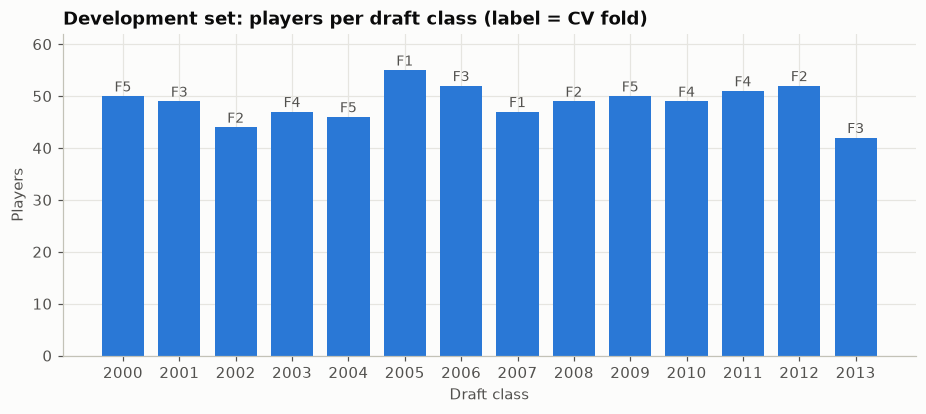

draft_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
players,50,49,44,47,46,55,52,47,49,50,49,51,52,42
fold,5,3,2,4,5,1,3,1,2,5,4,4,2,3


In [2]:
from sklearn.model_selection import GroupKFold

folds = GroupKFold(n_splits=m.N_FOLDS)
fold_of = pd.Series(0, index=dev.index)
for k, (_, va) in enumerate(folds.split(dev, groups=dev["draft_year"])):
    fold_of.iloc[va] = k + 1

per_class = dev.groupby("draft_year").agg(players=("player_id", "size"))
per_class["fold"] = dev.groupby("draft_year").apply(lambda g: fold_of[g.index].iloc[0])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(per_class.index, per_class["players"], color=BLUE, width=0.75)
for year, row in per_class.iterrows():
    ax.annotate(f"F{row['fold']}", (year, row["players"]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set(title="Development set: players per draft class (label = CV fold)",
       xlabel="Draft class", ylabel="Players", ylim=(0, 62))
ax.set_xticks(per_class.index)
plt.show()
per_class.T

**What to look for:** every class sits entirely inside one fold, so a model is
never validated on a class it partly trained on. Fewer players in recent classes
is expected: late debuts from those classes had no completed year 4 by 2016-17.

### Walk-forward test (used only at the very end)
Each test class gets its own model, trained on what was known when that class
played its rookie season.

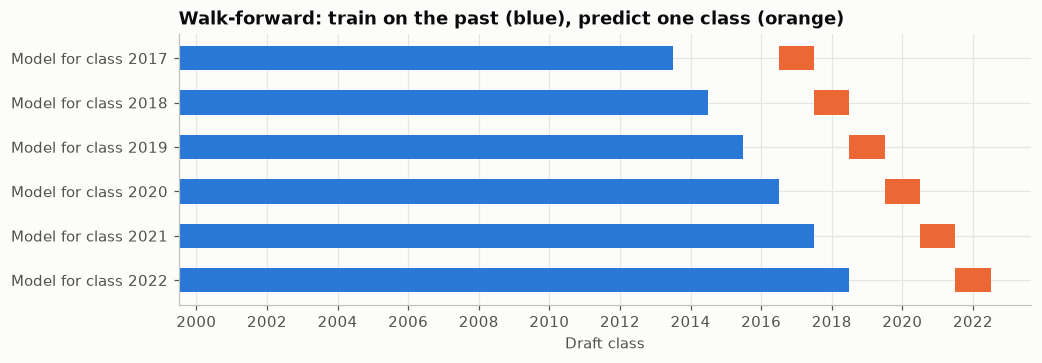

,test class,train players,latest train class,test players
0,2017,683,2013,56
1,2018,735,2014,57
2,2019,783,2015,58
3,2020,837,2016,58
4,2021,897,2017,55
5,2022,955,2018,47


In [3]:
wf = pd.DataFrame({
    "test class": m.TEST_CLASSES,
    "train players": [m.known_before(df, c).sum() for c in m.TEST_CLASSES],
    "latest train class": [df.loc[m.known_before(df, c), "draft_year"].max() for c in m.TEST_CLASSES],
    "test players": [(df["draft_year"] == c).sum() for c in m.TEST_CLASSES],
})

fig, ax = plt.subplots(figsize=(10, 3.2))
for i, row in wf.iterrows():
    ax.barh(i, row["latest train class"] - 2000 + 1, left=2000 - 0.5, color=BLUE, height=0.55)
    ax.barh(i, 1, left=row["test class"] - 0.5, color=ORANGE, height=0.55)
ax.set_yticks(range(len(wf)), [f"Model for class {c}" for c in wf["test class"]])
ax.invert_yaxis()
ax.set(title="Walk-forward: train on the past (blue), predict one class (orange)",
       xlabel="Draft class")
ax.set_xticks(range(2000, 2023, 2))
plt.show()
wf

**What to look for:** the gap between the last blue class and the orange one.
That gap is the time it takes for a class's year 4 to finish: e.g. the model
for 2017 only learns from classes up to ~2013.

## 2. Baseline: draft pick only

The baseline must be **strong**: beating a weak baseline proves nothing.
Candidates, all using only the pick:

| Candidate | Idea |
|---|---|
| Mean only | predicts the average for everyone (the floor, not a real candidate) |
| Linear on pick | a straight line: each pick later loses the same value |
| Quadratic on log(pick) | value falls fast at the top and flattens later |
| Isotonic on pick | any decreasing curve, learned from the data |

Each is scored with the same grouped 5-fold CV.

In [4]:
def log_terms(X):
    lp = np.log(np.asarray(X, dtype=float))
    return np.column_stack([lp, lp ** 2])

CANDIDATES = {
    "Mean only": lambda: DummyRegressor(strategy="mean"),
    "Linear on pick": lambda: LinearRegression(),
    "Quadratic on log(pick)": lambda: make_pipeline(FunctionTransformer(log_terms), LinearRegression()),
    "Isotonic on pick": lambda: IsotonicRegression(increasing=False, out_of_bounds="clip"),
}

results, fold_tables, oof_preds = {}, {}, {}
for name, make in CANDIDATES.items():
    folds_df, oof = m.cross_validate(make, ["pick"], dev)
    fold_tables[name], oof_preds[name] = folds_df, oof
    results[name] = m.summarize(folds_df)

summary = pd.DataFrame(results).T
summary.round(3)

,rmse_mean,mae_mean,spearman_mean,rmse_std,mae_std,spearman_std
Mean only,2.313,1.561,NaN,0.336,0.088,NaN
Linear on pick,2.188,1.423,0.268,0.327,0.088,0.051
Quadratic on log(pick),2.119,1.381,0.268,0.297,0.083,0.052
Isotonic on pick,2.175,1.401,0.250,0.346,0.102,0.056


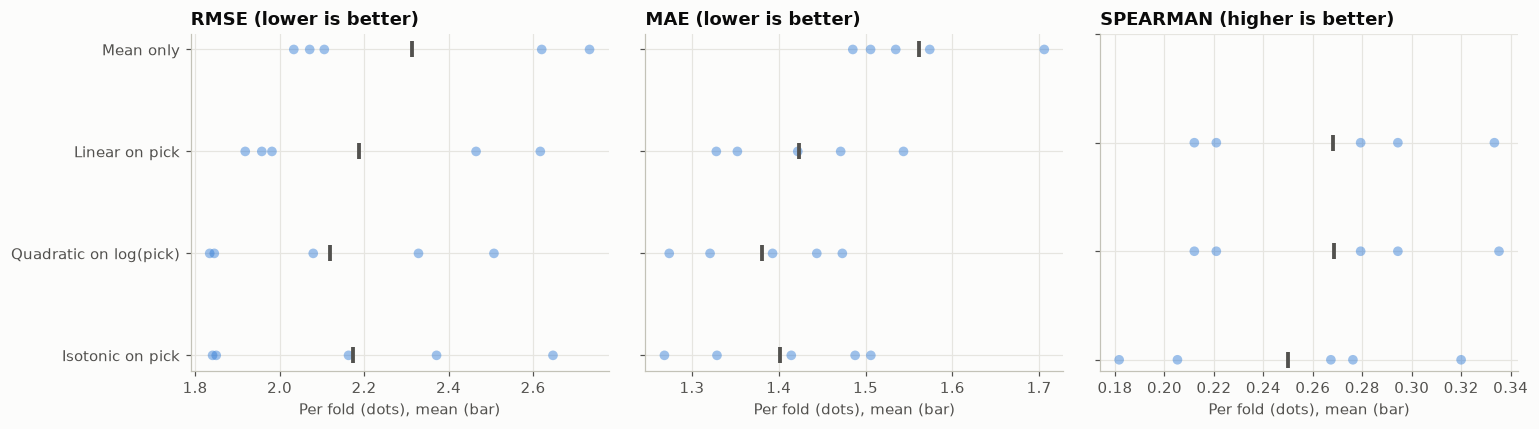

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
names = list(CANDIDATES)
for ax, metric, better in zip(axes, ["rmse", "mae", "spearman"], ["lower", "lower", "higher"]):
    for i, name in enumerate(names):
        vals = fold_tables[name][metric]
        ax.scatter(vals, [i] * len(vals), s=40, color=BLUE, alpha=0.45, edgecolor="none")
        ax.scatter(vals.mean(), i, s=110, marker="|", color=INK_2, linewidths=2.5)
    ax.set_yticks(range(len(names)), names if metric == "rmse" else [""] * len(names))
    ax.invert_yaxis()
    ax.set(title=f"{metric.upper()} ({better} is better)", xlabel="Per fold (dots), mean (bar)")
plt.tight_layout()
plt.show()

**What to look for:** not just which mean is best, but whether a candidate wins
*consistently* across folds (dots shifted together) or only on average. Folds
differ a lot because a single superstar in a fold (e.g. Chris Paul, LeBron)
moves its RMSE.

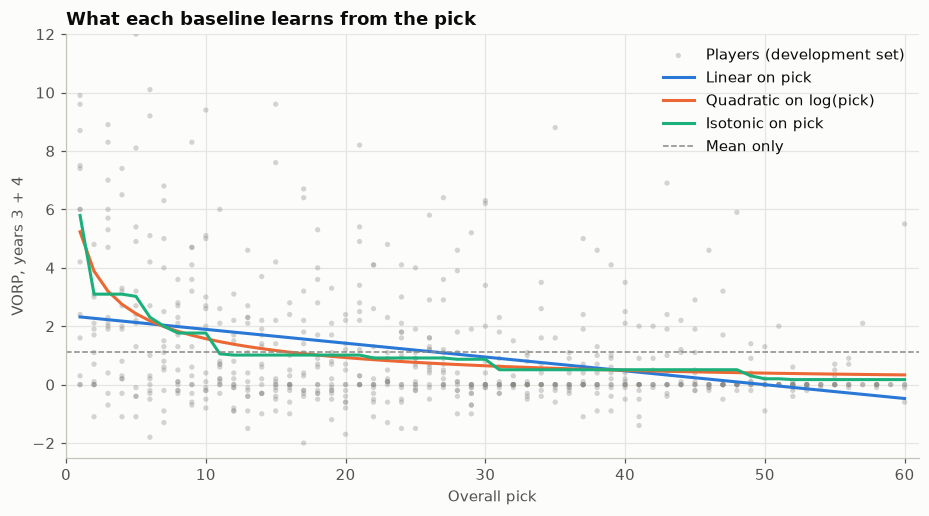

In [6]:
grid = pd.DataFrame({"pick": np.arange(1, 61)})
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(dev["pick"], dev[m.TARGET], s=12, color=NEUTRAL, alpha=0.35, edgecolor="none",
           label="Players (development set)")
for name, color in zip(names[1:], [BLUE, ORANGE, AQUA]):
    fitted = CANDIDATES[name]().fit(dev[["pick"]], dev[m.TARGET])
    ax.plot(grid["pick"], fitted.predict(grid[["pick"]]), color=color, label=name)
ax.axhline(dev[m.TARGET].mean(), color=NEUTRAL, linewidth=1, linestyle="--", label="Mean only")
ax.set(title="What each baseline learns from the pick", xlabel="Overall pick",
       ylabel="VORP, years 3 + 4", ylim=(-2.5, 12), xlim=(0, 61))
ax.legend(loc="upper right")
plt.show()

**What to look for:** the straight line can't follow the steep drop at the top
picks; the log and isotonic curves can. The y-axis is cut at 12 to show the
curves, so a few stars sit above the plot.

In [7]:
BASELINE = summary["rmse_mean"].drop("Mean only").idxmin()
print(f"Chosen baseline (lowest mean RMSE): {BASELINE}")

# How often does the chosen baseline beat each other candidate, fold by fold?
wins = {name: int((fold_tables[BASELINE]["rmse"] < fold_tables[name]["rmse"]).sum())
        for name in names if name != BASELINE}
print("Folds (out of 5) where it has lower RMSE than:", wins)

Chosen baseline (lowest mean RMSE): Quadratic on log(pick)
Folds (out of 5) where it has lower RMSE than: {'Mean only': 4, 'Linear on pick': 4, 'Isotonic on pick': 4}


,rmse,mae,spearman,n
Picks 1-10,3.522,2.646,0.213,139
Picks 11-30,1.829,1.350,-0.018,267
2nd round,1.238,0.766,0.035,277


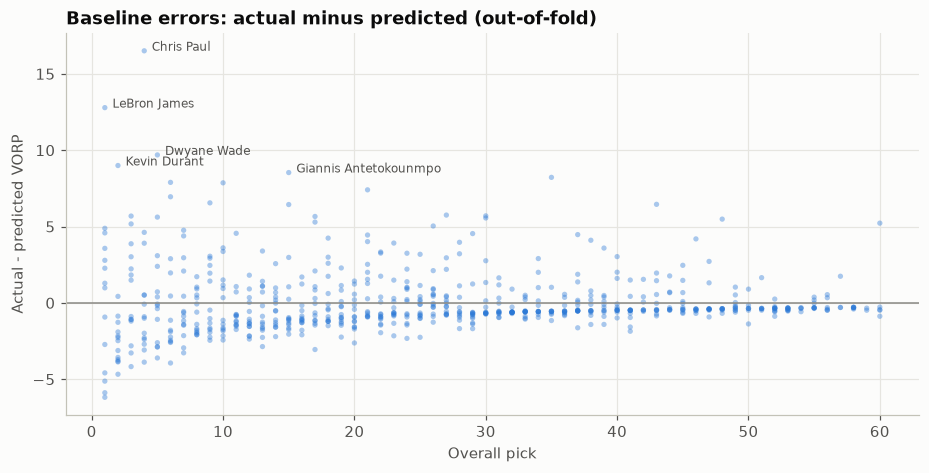

In [8]:
base_oof = oof_preds[BASELINE]
seg = m.by_segment(dev, base_oof)
display(seg.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
resid = dev[m.TARGET] - base_oof
ax.scatter(dev["pick"], resid, s=12, color=BLUE, alpha=0.4, edgecolor="none")
ax.axhline(0, color=NEUTRAL, linewidth=1)
for _, row in dev.assign(resid=resid).nlargest(5, "resid").iterrows():
    ax.annotate(row["player_name"], (row["pick"], row["resid"]), xytext=(5, 0),
                textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title="Baseline errors: actual minus predicted (out-of-fold)",
       xlabel="Overall pick", ylabel="Actual - predicted VORP")
plt.show()

**What to look for:** the errors are what the early-game model has to explain.
Big positive errors are steals and stars the pick couldn't see coming; big
negative ones are busts. Errors are much larger at the top picks (where the
stakes are highest), which is why RMSE is the main metric.

In [9]:
cols = ["player_name", "draft_year", "pick", "mpg", "ts_pct", m.TARGET]
view = dev.assign(baseline_pred=base_oof, error=dev[m.TARGET] - base_oof)
print("Baseline's biggest under-predictions (the pick missed a good player)")
display(view.nlargest(8, "error")[cols + ["baseline_pred", "error"]].round(2))
print("Baseline's biggest over-predictions (the pick promised more)")
display(view.nsmallest(8, "error")[cols + ["baseline_pred", "error"]].round(2))

Baseline's biggest under-predictions (the pick missed a good player)


,player_name,draft_year,pick,mpg,ts_pct,target_vorp,baseline_pred,error
239,Chris Paul,2005,4,36.76,-0.01,19.2,2.69,16.51
143,LeBron James,2003,1,40.12,-0.03,17.5,4.71,12.79
147,Dwyane Wade,2003,5,36.22,-0.03,12.0,2.31,9.69
344,Kevin Durant,2007,2,33.32,-0.04,12.8,3.80,9.00
654,Giannis Antetokounmpo,2013,15,19.40,-0.00,9.6,1.06,8.54
621,Draymond Green,2012,35,14.72,-0.11,8.8,0.58,8.22
296,Brandon Roy,2006,6,27.20,-0.05,10.1,2.21,7.89
498,Paul George,2010,10,16.38,-0.06,9.4,1.54,7.86


Baseline's biggest over-predictions (the pick promised more)


,player_name,draft_year,pick,mpg,ts_pct,target_vorp,baseline_pred,error
641,Anthony Bennett,2013,1,10.10,-0.12,0.0,6.18,-6.18
50,Kwame Brown,2001,1,13.50,-0.06,0.3,6.18,-5.88
343,Greg Oden,2007,1,23.05,-0.01,0.0,5.12,-5.12
490,Evan Turner,2010,2,23.88,-0.06,-1.1,3.57,-4.67
291,Andrea Bargnani,2006,1,20.12,-0.03,1.6,6.18,-4.58
293,Adam Morrison,2006,3,33.52,-0.08,-0.7,3.47,-4.17
348,Yi Jianlian,2007,6,27.32,-0.02,-1.8,2.14,-3.94
592,Dion Waiters,2012,4,32.06,-0.06,-1.1,2.78,-3.88


## Baseline result (to beat)

The chosen baseline's cross-validated scores are the bar every model in the next
step has to clear:

In [10]:
baseline_score = summary.loc[BASELINE]
baseline_score.round(3)

rmse_mean        2.119
mae_mean         1.381
spearman_mean    0.268
rmse_std         0.297
mae_std          0.083
spearman_std     0.052
Name: Quadratic on log(pick), dtype: float64

## 3. Models with the window features

### Feature groups
The pick enters as log(pick) and log(pick)², exactly like the baseline, so every
model already "contains" the baseline and the window features only have to
explain what the pick doesn't.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_pinball_loss
from sklearn.preprocessing import SplineTransformer, StandardScaler

for d in (df, dev):
    d["log_pick"] = np.log(d["pick"])
    d["log_pick2"] = d["log_pick"] ** 2

PICK = ["log_pick", "log_pick2"]
CONTEXT = ["age_at_debut", "debut_lag", "team_win_pct"]
OPPORTUNITY = ["mpg", "games_played_share", "minutes"]
PRODUCTION = ["ts_pct", "fg3_pct", "fg3a_rate", "fta_rate", "pts36", "usg_pct",
              "ast36", "tov_pct", "orb_pct", "drb_pct", "stl36", "blk36", "pf36", "pm36"]
ALL = PICK + CONTEXT + OPPORTUNITY + PRODUCTION
print(f"{len(ALL)} features: {len(PICK)} pick, {len(CONTEXT)} context, "
      f"{len(OPPORTUNITY)} opportunity, {len(PRODUCTION)} production")

22 features: 2 pick, 3 context, 3 opportunity, 14 production


### The candidates
Each factory returns a fresh, unfitted model, so every fold starts clean.

- **Ridge**: scale the features (inside each fold), then a penalised linear regression.
  `alpha` = how strong the penalty is.
- **Ridge + splines**: every non-pick feature is replaced by a smooth curve
  (cubic splines, 5 knots), so U shapes are possible. Still a sum of one curve
  per feature, so each curve can be plotted and explained.
- **Gradient boosting**: many small trees, each fixing the previous ones' errors.
  Small trees (`max_leaf_nodes`), many players per leaf (`min_samples_leaf`) and a
  slow learning rate keep it from memorising noise.

In [12]:
def ridge(alpha):
    return lambda: make_pipeline(StandardScaler(), Ridge(alpha=alpha))


def spline_ridge(alpha, features=ALL):
    pick = [f for f in features if f in PICK]
    curves = [f for f in features if f not in PICK]
    return lambda: make_pipeline(
        ColumnTransformer([
            ("pick", "passthrough", pick),
            ("curves", SplineTransformer(n_knots=5, degree=3), curves),
        ]),
        StandardScaler(),
        Ridge(alpha=alpha),
    )


def boosting(leaves, min_leaf, iters, loss="squared_error", quantile=None):
    params = dict(loss=loss, learning_rate=0.03, max_iter=iters,
                  max_leaf_nodes=leaves, min_samples_leaf=min_leaf,
                  l2_regularization=1.0, early_stopping=False, random_state=0)
    if quantile is not None:
        params["quantile"] = quantile
    return lambda: HistGradientBoostingRegressor(**params)


def tune(factories, features=ALL):
    """Plain grouped 5-fold CV for each configuration (same folds as the baseline)."""
    rows = []
    for label, make in factories.items():
        folds_df, _ = m.cross_validate(make, features, dev)
        rows.append({"config": label, **m.summarize(folds_df)})
    return pd.DataFrame(rows).set_index("config")

### Tuning
Small grids, scored with the same 5 folds as the baseline (RMSE 2.119 to beat).
Choosing settings on the same CV that scores them is slightly optimistic; the
walk-forward test at the end is the number that doesn't flatter.

In [13]:
ALPHAS = [1, 3, 10, 30, 100, 300, 1000]
ridge_tune = tune({a: ridge(a) for a in ALPHAS})
spline_tune = tune({a: spline_ridge(a) for a in ALPHAS})

GRID = [(l, s, i) for l in (4, 8) for s in (20, 40) for i in (150, 300)]
hgb_tune = tune({g: boosting(*g) for g in GRID})

best_alpha = ridge_tune["rmse_mean"].idxmin()
best_spline_alpha = spline_tune["rmse_mean"].idxmin()
best_grid = hgb_tune["rmse_mean"].idxmin()
print(f"Ridge best alpha: {best_alpha}  (RMSE {ridge_tune.loc[best_alpha, 'rmse_mean']:.3f})")
print(f"Ridge + splines best alpha: {best_spline_alpha}  (RMSE {spline_tune.loc[best_spline_alpha, 'rmse_mean']:.3f})")
print(f"Boosting best (leaves, min_leaf, iters): {best_grid}  (RMSE {hgb_tune.loc[[best_grid], 'rmse_mean'].iloc[0]:.3f})")

Ridge best alpha: 30  (RMSE 1.900)
Ridge + splines best alpha: 300  (RMSE 1.897)
Boosting best (leaves, min_leaf, iters): (8, 40, 300)  (RMSE 1.959)


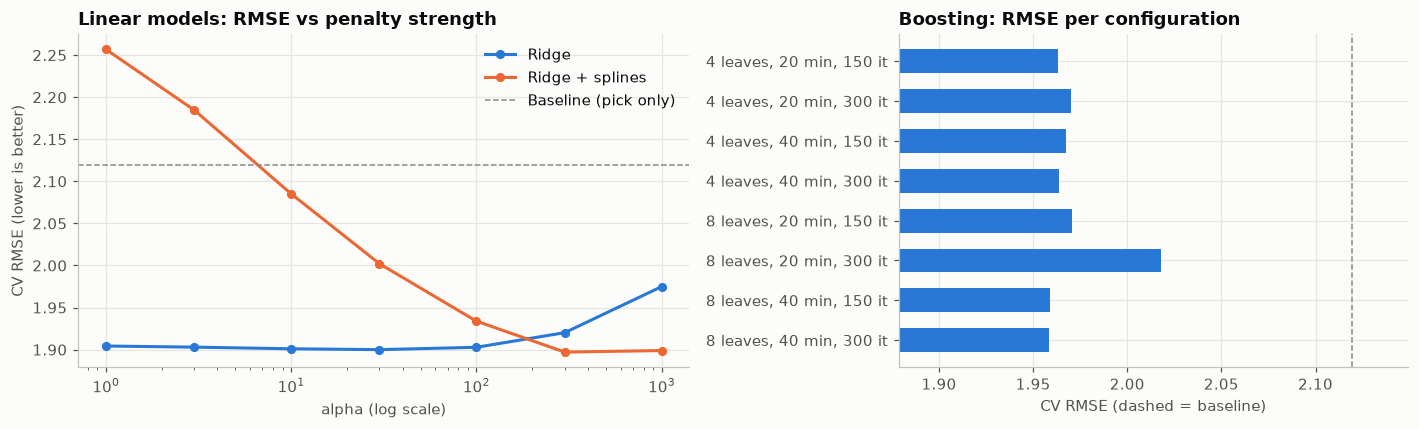

In [14]:
base_rmse = baseline_score["rmse_mean"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.2, 1]})

ax = axes[0]
for name, table, color in [("Ridge", ridge_tune, BLUE), ("Ridge + splines", spline_tune, ORANGE)]:
    ax.plot(table.index, table["rmse_mean"], color=color, marker="o", markersize=5, label=name)
ax.axhline(base_rmse, color=NEUTRAL, linestyle="--", linewidth=1, label="Baseline (pick only)")
ax.set_xscale("log")
ax.set(title="Linear models: RMSE vs penalty strength", xlabel="alpha (log scale)",
       ylabel="CV RMSE (lower is better)")
ax.legend()

ax = axes[1]
labels = [f"{l} leaves, {s} min, {i} it" for l, s, i in hgb_tune.index]
ax.barh(labels, hgb_tune["rmse_mean"], color=BLUE, height=0.6)
ax.axvline(base_rmse, color=NEUTRAL, linestyle="--", linewidth=1)
ax.set_xlim(hgb_tune["rmse_mean"].min() - 0.08, base_rmse + 0.03)
ax.invert_yaxis()
ax.set(title="Boosting: RMSE per configuration", xlabel="CV RMSE (dashed = baseline)")
plt.tight_layout()
plt.show()

**What to look for:** the left chart's U shape. Too little penalty (left) lets the
model chase noise; too much (right) flattens it back toward the baseline. The best
alpha sits in the valley. For boosting, the gaps between configurations are small,
which is good: the result doesn't hinge on one lucky setting.

### Head-to-head: repeated cross-validation
Every candidate (and the baseline) is scored on the **same** 25 splits
(5 repeats × 5 folds), so differences are paired fold by fold.

In [15]:
best_linear = (("Ridge + splines", spline_ridge(best_spline_alpha))
               if spline_tune["rmse_mean"].min() < ridge_tune["rmse_mean"].min()
               else ("Ridge", ridge(best_alpha)))
FINAL = {
    "Baseline (pick only)": (lambda: make_pipeline(FunctionTransformer(log_terms), LinearRegression()), ["pick"]),
    "Ridge": (ridge(best_alpha), ALL),
    "Ridge + splines": (spline_ridge(best_spline_alpha), ALL),
    "Gradient boosting": (boosting(*best_grid), ALL),
    f"Ensemble ({best_linear[0]} + boosting)": (
        lambda: VotingRegressor([("linear", best_linear[1]()), ("boosting", boosting(*best_grid)())]), ALL),
}

rep_tables, rep_oof = {}, {}
for name, (make, feats) in FINAL.items():
    rep_tables[name], rep_oof[name] = m.repeated_cv(make, feats, dev, repeats=5)

base_folds = rep_tables["Baseline (pick only)"]
rows = {}
for name, t in rep_tables.items():
    s = t[["rmse", "mae", "spearman"]]
    rows[name] = {
        "RMSE": s["rmse"].mean(), "RMSE sd": s["rmse"].std(),
        "MAE": s["mae"].mean(), "Spearman": s["spearman"].mean(),
        "beats baseline (of 25)": int((t["rmse"].values < base_folds["rmse"].values).sum())
        if name != "Baseline (pick only)" else None,
        "beats Ridge (of 25)": int((t["rmse"].values < rep_tables["Ridge"]["rmse"].values).sum())
        if name not in ("Baseline (pick only)", "Ridge") else None,
    }
compare = pd.DataFrame(rows).T
compare.round(3)

,RMSE,RMSE sd,MAE,Spearman,beats baseline (of 25),beats Ridge (of 25)
Baseline (pick only),2.102,0.207,1.377,0.274,NaN,NaN
Ridge,1.904,0.163,1.248,0.467,24.0,NaN
Ridge + splines,1.905,0.169,1.242,0.441,22.0,13.0
Gradient boosting,1.958,0.138,1.275,0.407,21.0,5.0
Ensemble (Ridge + splines + boosting),1.889,0.151,1.230,0.438,24.0,15.0


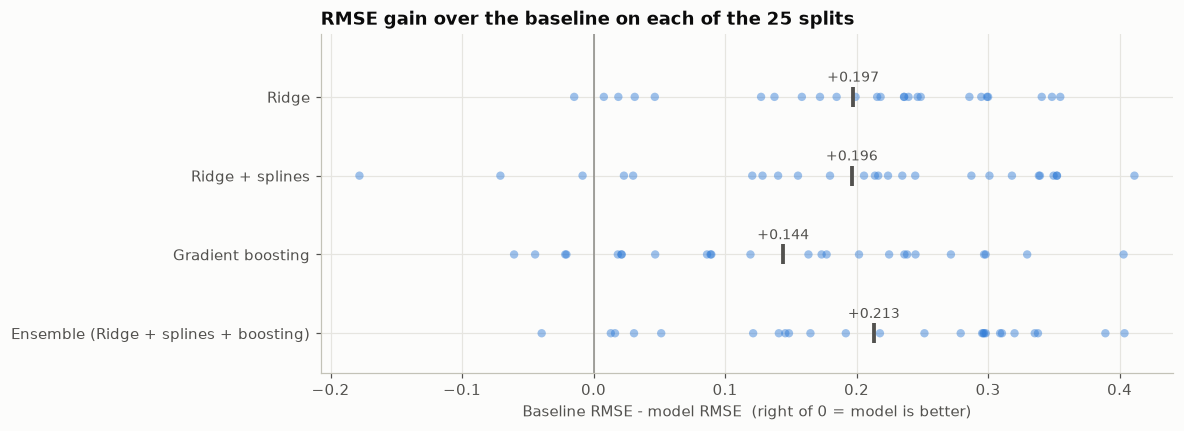

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
models = [n for n in FINAL if n != "Baseline (pick only)"]
for i, name in enumerate(models):
    gain = base_folds["rmse"].values - rep_tables[name]["rmse"].values
    ax.scatter(gain, [i] * len(gain), s=30, color=BLUE, alpha=0.45, edgecolor="none")
    ax.scatter(gain.mean(), i, s=160, marker="|", color=INK_2, linewidths=2.5)
    ax.annotate(f"{gain.mean():+.3f}", (gain.mean(), i), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_yticks(range(len(models)), models)
ax.set_ylim(len(models) - 0.5, -0.8)
ax.set(title="RMSE gain over the baseline on each of the 25 splits",
       xlabel="Baseline RMSE - model RMSE  (right of 0 = model is better)")
plt.show()

**What to look for:** dots to the right of 0 are splits where the model beat the
pick-only baseline. A model that helps for real has almost all its dots on the
right, not just a positive average pulled by a couple of splits.

In [17]:
BEST = compare.drop("Baseline (pick only)")["RMSE"].idxmin()
print(f"Best model by repeated CV: {BEST}")
best_oof = rep_oof[BEST]
base_oof_rep = rep_oof["Baseline (pick only)"]

seg_compare = pd.concat({
    "Baseline": m.by_segment(dev, base_oof_rep)[["rmse", "spearman"]],
    BEST: m.by_segment(dev, best_oof)[["rmse", "spearman", "n"]],
}, axis=1)
seg_compare.round(3)

Best model by repeated CV: Ensemble (Ridge + splines + boosting)


Baseline          Ensemble (Ridge + splines + boosting)           \
                rmse spearman                                  rmse spearman   
Picks 1-10     3.515    0.191                                 2.998    0.521   
Picks 11-30    1.831   -0.035                                 1.672    0.400   
2nd round      1.240    0.010                                 1.221    0.273   

                  
               n  
Picks 1-10   139  
Picks 11-30  267  
2nd round    277

**What to look for:** *where* the gain comes from. The notes predicted it would be
at the top picks (stars and busts) and in the steals; this table shows whether
that's true. Spearman inside a segment is the ranking quality among players
picked in similar spots, where the pick alone can barely rank anyone.

### Where does the gain come from? (ablation)
Feature groups are added one layer at a time. The step from C to D is the key
one: does what the rookie *does on the court* add anything beyond how much the
coach *plays him*?

In [18]:
LAYERS = {
    "A. Pick": PICK,
    "B. + Context": PICK + CONTEXT,
    "C. + Opportunity": PICK + CONTEXT + OPPORTUNITY,
    "D. + Production": ALL,
}
ablation = {}
for model_name, factory in [(best_linear[0], lambda f: spline_ridge(best_spline_alpha, f)
                              if best_linear[0] == "Ridge + splines" else ridge(best_alpha)),
                             ("Gradient boosting", lambda f: boosting(*best_grid))]:
    ablation[model_name] = {}
    for layer, feats in LAYERS.items():
        t, _ = m.repeated_cv(factory(feats), feats, dev, repeats=5)
        ablation[model_name][layer] = t["rmse"].mean()
ablation = pd.DataFrame(ablation)
ablation.round(3)

,Ridge + splines,Gradient boosting
A. Pick,2.123,2.149
B. + Context,2.122,2.209
C. + Opportunity,1.939,2.020
D. + Production,1.905,1.958


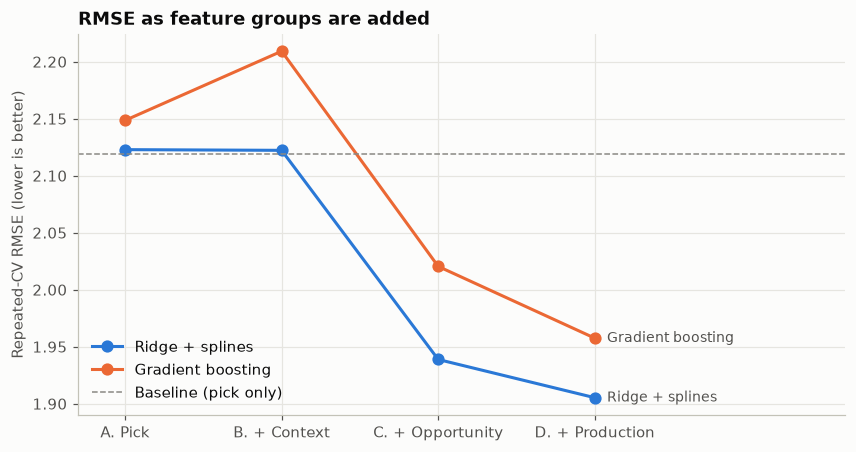

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, col), color in zip(ablation.items(), [BLUE, ORANGE]):
    ax.plot(range(len(col)), col.values, color=color, marker="o", markersize=7, label=name)
    ax.annotate(name, (len(col) - 1, col.values[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK_2)
ax.axhline(base_rmse, color=NEUTRAL, linestyle="--", linewidth=1, label="Baseline (pick only)")
ax.set_xticks(range(len(LAYERS)), list(LAYERS), rotation=0)
ax.set_xlim(-0.3, len(LAYERS) - 0.3 + 0.9)
ax.set(title="RMSE as feature groups are added", ylabel="Repeated-CV RMSE (lower is better)")
ax.legend(loc="lower left")
plt.show()

**What to look for:** the size of each drop. A big drop at C and a flat line at D
would mean "the first games matter because of how much the coach trusts the
rookie". A clear drop at D means the box-score production adds its own signal.

### Calibration: is the model too conservative at the top?
Players are grouped into 10 bins by predicted value; each dot is the bin's average
prediction vs its average real outcome. A perfectly calibrated model sits on the
diagonal. Dots *above* the diagonal at the right end mean the model under-predicts
its best prospects.

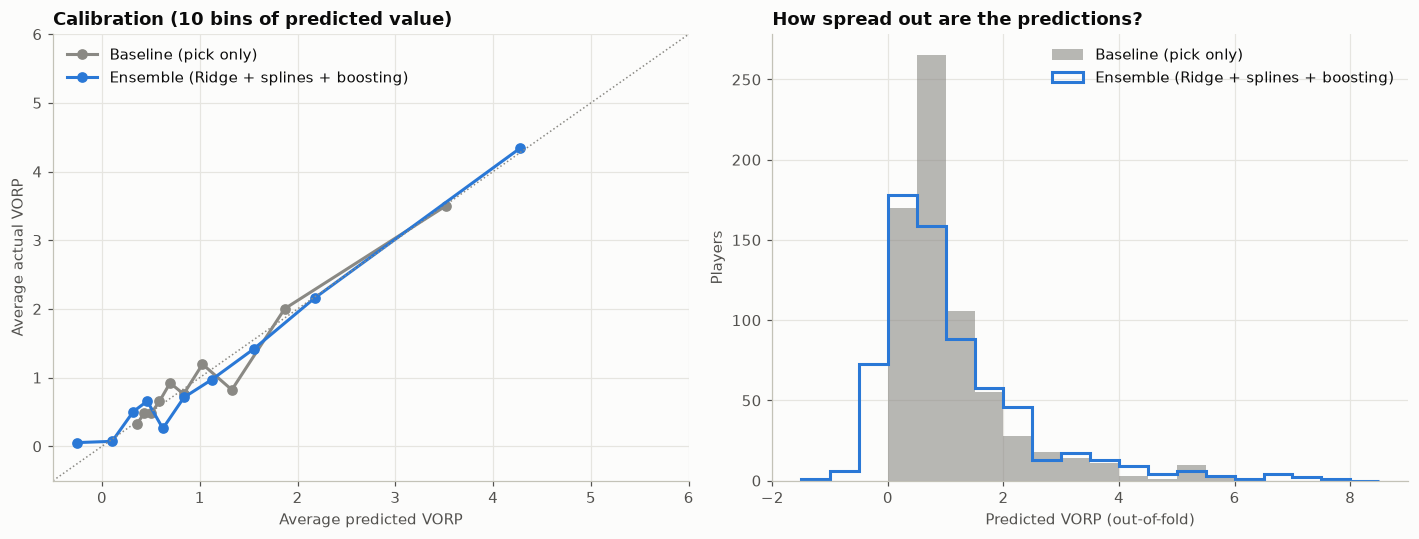

Highest prediction - baseline: 5.6, Ensemble (Ridge + splines + boosting): 8.8
Players predicted >= 5 - baseline: 12, Ensemble (Ridge + splines + boosting): 18


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for name, pred, color in [("Baseline (pick only)", base_oof_rep, NEUTRAL), (BEST, best_oof, BLUE)]:
    q = pd.qcut(pred.rank(method="first"), 10, labels=False)
    g = pd.DataFrame({"pred": pred, "actual": dev[m.TARGET]}).groupby(q).mean()
    ax.plot(g["pred"], g["actual"], color=color, marker="o", markersize=6, label=name)
lim = [-0.5, 6]
ax.plot(lim, lim, color=NEUTRAL, linewidth=1, linestyle=":")
ax.set(title="Calibration (10 bins of predicted value)", xlabel="Average predicted VORP",
       ylabel="Average actual VORP", xlim=lim, ylim=lim)
ax.legend(loc="upper left")

ax = axes[1]
bins = np.arange(-1.5, 9, 0.5)
ax.hist(base_oof_rep, bins=bins, color=NEUTRAL, alpha=0.6, label="Baseline (pick only)")
ax.hist(best_oof, bins=bins, histtype="step", color=BLUE, linewidth=2, label=BEST)
ax.set(title="How spread out are the predictions?", xlabel="Predicted VORP (out-of-fold)",
       ylabel="Players")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Highest prediction - baseline: {base_oof_rep.max():.1f}, {BEST}: {best_oof.max():.1f}")
print(f"Players predicted >= 5 - baseline: {(base_oof_rep >= 5).sum()}, {BEST}: {(best_oof >= 5).sum()}")

**What to look for:** on the left, how close each line stays to the diagonal,
especially at the top bin. On the right, whether the model's predictions spread
wider than the baseline's (which can only spread as far as the pick curve goes).
A wider spread means the model is less "conservative" and is willing to call
some rookies high-upside.

### Floor and ceiling: quantile models
Instead of the average outcome, gradient boosting can predict a **percentile**:

- **10th percentile, the floor**: only 10% of similar players end up below it
- **50th percentile, the central case**
- **90th percentile, the ceiling**: only 10% end up above it

Checked two ways: the *pinball loss* (the proper error measure for a percentile,
lower is better) and the *coverage* (the share of players actually below each
line should be close to 10%, 50% and 90%).

In [21]:
QUANTILES = [0.1, 0.5, 0.9]
quant_oof = {}
for label, feats in [("pick only", PICK), ("all features", ALL)]:
    for q in QUANTILES:
        _, oof = m.repeated_cv(boosting(*best_grid, loss="quantile", quantile=q), feats, dev, repeats=5)
        quant_oof[(label, q)] = oof

rows = []
for label in ["pick only", "all features"]:
    preds = np.sort(np.column_stack([quant_oof[(label, q)] for q in QUANTILES]), axis=1)  # no crossing
    for j, q in enumerate(QUANTILES):
        rows.append({"features": label, "percentile": f"p{int(q * 100)}",
                     "pinball loss": mean_pinball_loss(dev[m.TARGET], preds[:, j], alpha=q),
                     "share of players below": (dev[m.TARGET] < preds[:, j]).mean()})
    quant_oof[(label, "sorted")] = preds
quant_table = pd.DataFrame(rows).set_index(["features", "percentile"])
quant_table.round(3)

pinball loss  share of players below
features     percentile                                      
pick only    p10                0.193                   0.114
             p50                0.627                   0.580
             p90                0.473                   0.877
all features p10                0.188                   0.142
             p50                0.577                   0.536
             p90                0.417                   0.854

**What to look for:** lower pinball loss with all features than with the pick
only, especially at p90 (the features should mostly help to spot the ceiling).
Coverage close to 10% / 50% / 90% means the lines can be trusted as stated.

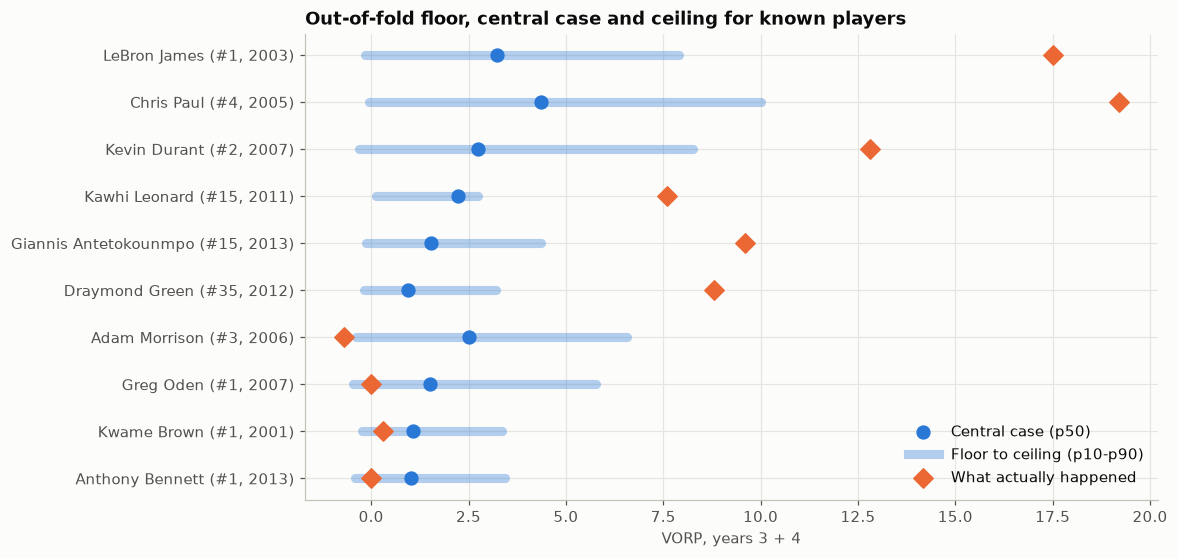

In [22]:
SHOWCASE = ["LeBron James", "Chris Paul", "Kevin Durant", "Kawhi Leonard",
            "Giannis Antetokounmpo", "Draymond Green", "Adam Morrison",
            "Greg Oden", "Kwame Brown", "Anthony Bennett"]
preds = quant_oof[("all features", "sorted")]
show = dev.assign(p10=preds[:, 0], p50=preds[:, 1], p90=preds[:, 2])
show = show[show["player_name"].isin(SHOWCASE)].set_index("player_name").reindex(SHOWCASE).dropna(how="all")

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (name, row) in enumerate(show.iterrows()):
    ax.plot([row["p10"], row["p90"]], [i, i], color=BLUE, linewidth=6, alpha=0.35,
            solid_capstyle="round")
    ax.scatter(row["p50"], i, s=70, color=BLUE, zorder=3)
    ax.scatter(row[m.TARGET], i, s=80, marker="D", color=ORANGE, zorder=4)
ax.set_yticks(range(len(show)), [f"{n} (#{int(r['pick'])}, {int(r['draft_year'])})"
                                 for n, r in show.iterrows()])
ax.invert_yaxis()
ax.scatter([], [], s=70, color=BLUE, label="Central case (p50)")
ax.plot([], [], color=BLUE, linewidth=6, alpha=0.35, label="Floor to ceiling (p10-p90)")
ax.scatter([], [], s=80, marker="D", color=ORANGE, label="What actually happened")
ax.set(title="Out-of-fold floor, central case and ceiling for known players",
       xlabel="VORP, years 3 + 4")
ax.legend(loc="lower right")
plt.show()

**What to look for:** whether the stars' ceilings reach toward what they became,
and whether the busts' central cases sat lower than their draft slot promised.
Remember these are out-of-fold: each player was predicted by models that never
saw him. A diamond far outside its bar is a genuine surprise the first 25 games
couldn't show.